# EDA: ticket dataset
Short look at the cleaned data from `src/data.py` (Bitext customer support, mapped to 4 triage labels). Run `python -m src.data` first.

In [1]:
import sys; sys.path.insert(0, '..')  # so `src` imports work from notebooks/
import pandas as pd, matplotlib.pyplot as plt
from src.data import load_split, INTENT_TO_LABEL
splits = {n: load_split(n, '../data/processed') for n in ('train', 'val', 'test')}
train = splits['train']
pd.DataFrame({n: f['label'].value_counts() for n, f in splits.items()})

,train,val,test
label,,,
billing,5843,731,731
general,5786,723,723
account,4286,536,536
shipping,3503,438,438


## Class balance
Stratified splitting should give the same class proportions in every split.

In [2]:
props = pd.DataFrame({n: f['label'].value_counts(normalize=True) for n, f in splits.items()}).round(3)
props

,train,val,test
label,,,
billing,0.301,0.301,0.301
general,0.298,0.298,0.298
account,0.221,0.221,0.221
shipping,0.180,0.180,0.180


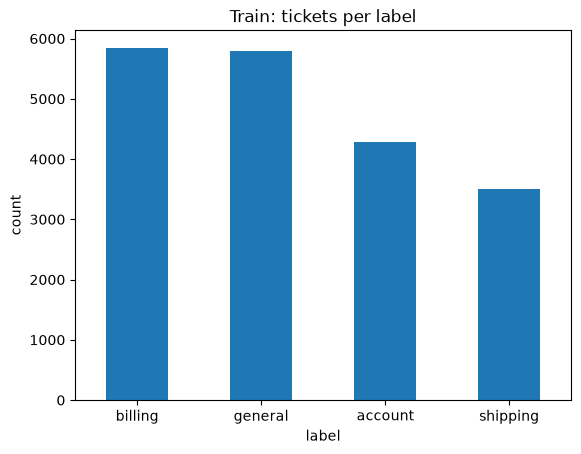

In [3]:
train['label'].value_counts().plot.bar(title='Train: tickets per label', rot=0)
plt.ylabel('count'); plt.show()

## Text length
Tickets are short, so a 64-token max length will be enough for DistilBERT in Phase 3.

count    19418.0
mean         8.9
std          2.6
min          1.0
25%          7.0
50%          9.0
75%         11.0
max         16.0
Name: n_words, dtype: float64


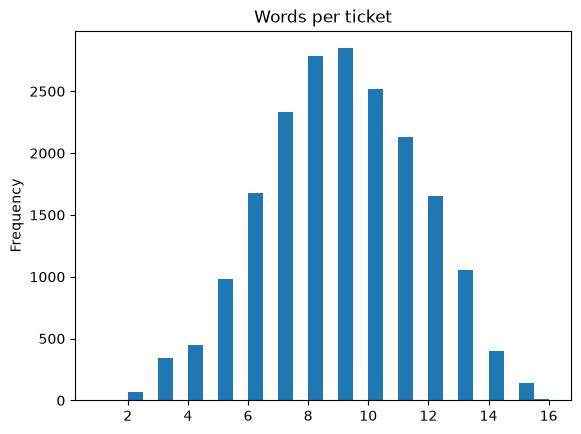

In [4]:
train['n_words'] = train['text'].str.split().str.len()
print(train['n_words'].describe().round(1))
train['n_words'].plot.hist(bins=30, title='Words per ticket'); plt.show()

## Examples per label

In [5]:
for lab, g in train.groupby('label'):
    print(lab.upper()); print(g['text'].sample(4, random_state=0).to_string(index=False)); print()

ACCOUNT
             help recovering thr PIN of my profile
have problems with a {{Account Type}} account r...
           could you help me use the gold profile?
               how can I use the freemium account?

BILLING
     i have got to check the rebate current status
i dont know how i can notify of a trouble with ...
  where to get my damn bills from {{Person Name}}?
    I would like to request a damn refund of money

GENERAL
 I do not know how I can sign up to the newsletter
help to check what hours customer assistance av...
tell me what hours i can contact customer sasis...
                where do I purchase some articles?

SHIPPING
I want help checking when my shipment is going ...
           I want to set a new delivery address up
    how do I see how soon can I expect my package?
       want help setting a new delivery address up



## Placeholders
Bitext texts contain template slots like `{{Order Number}}`. Models may learn these as shortcuts, so keep it in mind when reading accuracy.

In [6]:
has_ph = train['text'].str.contains(r'\{\{.*?\}\}')
print(f'{has_ph.mean():.1%} of train tickets contain a placeholder')
print(train.groupby('label')['text'].apply(lambda s: s.str.contains(r'\{\{.*?\}\}').mean()).round(3))

17.5% of train tickets contain a placeholder
label
account     0.232
billing     0.133
general     0.167
shipping    0.191
Name: text, dtype: float64


## Intents behind each label
Useful context for Phase 3 error analysis.

In [7]:
pd.Series(INTENT_TO_LABEL).rename('label').reset_index().groupby('label')['index'].apply(list)

label
account     [create_account, delete_account, edit_account,...
billing     [check_invoice, get_invoice, check_payment_met...
general     [cancel_order, change_order, place_order, cont...
shipping    [change_shipping_address, set_up_shipping_addr...
Name: index, dtype: object

## Takeaways
- Four labels, moderately imbalanced (shipping smallest).
- Texts are short and synthetic/templated, so expect high accuracy; treat results as a pipeline demo, not real-world difficulty.
- No 'bug' class exists in this data.